In [ ]:
import torch
from torchvision import datasets, transforms
from torch.utils.data import DataLoader
import matplotlib.pyplot as plt

In [ ]:
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.1307,), (0.3081,))
])

In [ ]:
train_dataset = datasets.MNIST(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

test_dataset = datasets.MNIST(
    root="./data",
    train=False,
    download=True,
    transform=transform
)

100%|██████████| 9.91M/9.91M [00:00<00:00, 20.5MB/s]
100%|██████████| 28.9k/28.9k [00:00<00:00, 486kB/s]
100%|██████████| 1.65M/1.65M [00:00<00:00, 4.54MB/s]
100%|██████████| 4.54k/4.54k [00:00<00:00, 9.08MB/s]


In [ ]:
print("Training images:", len(train_dataset))
print("Testing images:", len(test_dataset))

Training images: 60000
Testing images: 10000


In [ ]:
train_loader = DataLoader(
    train_dataset,
    batch_size=64,
    shuffle=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=64,
    shuffle=False
)

In [ ]:
images, labels = next(iter(train_loader))

print("Image batch shape:", images.shape)
print("Label batch shape:", labels.shape)


Image batch shape: torch.Size([64, 1, 28, 28])
Label batch shape: torch.Size([64])


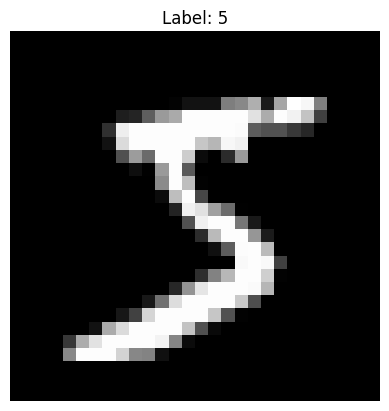

In [ ]:
image, label = train_dataset[0]

plt.imshow(image.squeeze(), cmap="gray")
plt.title(f"Label: {label}")
plt.axis("off")
plt.show()

In [ ]:
import torch.nn as nn
import torch.optim as optim

In [ ]:
class DigitCNN(nn.Module):

    def __init__(self):
        super(DigitCNN, self).__init__()

        # First convolution layer
        self.conv1 = nn.Conv2d(
            in_channels=1,
            out_channels=16,
            kernel_size=3,
            padding=1
        )

        # Second convolution layer
        self.conv2 = nn.Conv2d(
            in_channels=16,
            out_channels=32,
            kernel_size=3,
            padding=1
        )

        # Pooling layer
        self.pool = nn.MaxPool2d(2, 2)

        # Fully connected layers
        self.fc1 = nn.Linear(32 * 7 * 7, 128)
        self.fc2 = nn.Linear(128, 10)

        # Activation function
        self.relu = nn.ReLU()

    def forward(self, x):

        x = self.pool(self.relu(self.conv1(x)))
        x = self.pool(self.relu(self.conv2(x)))

        x = x.view(x.size(0), -1)

        x = self.relu(self.fc1(x))
        x = self.fc2(x)

        return x

In [ ]:
model = DigitCNN()

print(model)

DigitCNN(
  (conv1): Conv2d(1, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv2): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (pool): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (fc1): Linear(in_features=1568, out_features=128, bias=True)
  (fc2): Linear(in_features=128, out_features=10, bias=True)
  (relu): ReLU()
)


In [ ]:
criterion = nn.CrossEntropyLoss()

optimizer = optim.Adam(
    model.parameters(),
    lr=0.001
)

print("Loss function and optimizer created successfully!")

Loss function and optimizer created successfully!


In [ ]:
epochs = 5

for epoch in range(epochs):

    model.train()
    running_loss = 0.0

    for images, labels in train_loader:

        # Clear old gradients
        optimizer.zero_grad()

        # Make predictions
        outputs = model(images)

        # Calculate loss
        loss = criterion(outputs, labels)

        # Backpropagation
        loss.backward()

        # Update model weights
        optimizer.step()

        # Add loss
        running_loss += loss.item()

    average_loss = running_loss / len(train_loader)

    print(f"Epoch {epoch + 1}/{epochs}, Loss: {average_loss:.4f}")

print("Training completed!")

Epoch 1/5, Loss: 0.1587
Epoch 2/5, Loss: 0.0490
Epoch 3/5, Loss: 0.0332
Epoch 4/5, Loss: 0.0246
Epoch 5/5, Loss: 0.0196
Training completed!


In [ ]:
model.eval()

correct = 0
total = 0

with torch.no_grad():
    for images, labels in test_loader:

        outputs = model(images)

        _, predicted = torch.max(outputs, 1)

        total += labels.size(0)

        correct += (predicted == labels).sum().item()

accuracy = 100 * correct / total

print(f"Test Accuracy: {accuracy:.2f}%")

Test Accuracy: 98.92%


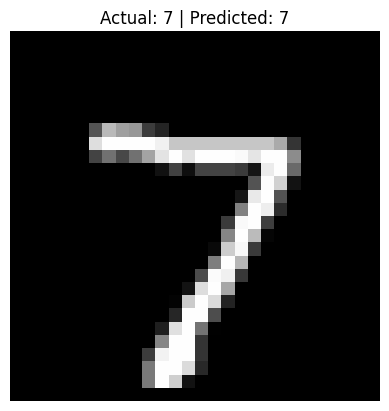

Actual digit: 7
Predicted digit: 7


In [ ]:
import matplotlib.pyplot as plt

# Get one image from the test dataset
image, actual_label = test_dataset[0]

# Add batch dimension
input_image = image.unsqueeze(0)

# Make prediction
model.eval()

with torch.no_grad():
    output = model(input_image)
    predicted_label = torch.argmax(output, dim=1).item()

# Show the image
plt.imshow(image.squeeze(), cmap="gray")
plt.title(f"Actual: {actual_label} | Predicted: {predicted_label}")
plt.axis("off")
plt.show()

print("Actual digit:", actual_label)
print("Predicted digit:", predicted_label)

In [ ]:
train_loader = DataLoader(
    train_dataset,
    batch_size=64,
    shuffle=True
)

test_loader = DataLoader(
    test_dataset,
    batch_size=64,
    shuffle=False
)

print("DataLoaders created successfully!")

DataLoaders created successfully!


In [ ]:
model.eval()

correct = 0
total = 0

with torch.no_grad():

    for images, labels in test_loader:

        outputs = model(images)

        _, predicted = torch.max(outputs, 1)

        total += labels.size(0)

        correct += (predicted == labels).sum().item()

accuracy = 100 * correct / total

print(f"Test Accuracy: {accuracy:.2f}%")

Test Accuracy: 98.92%


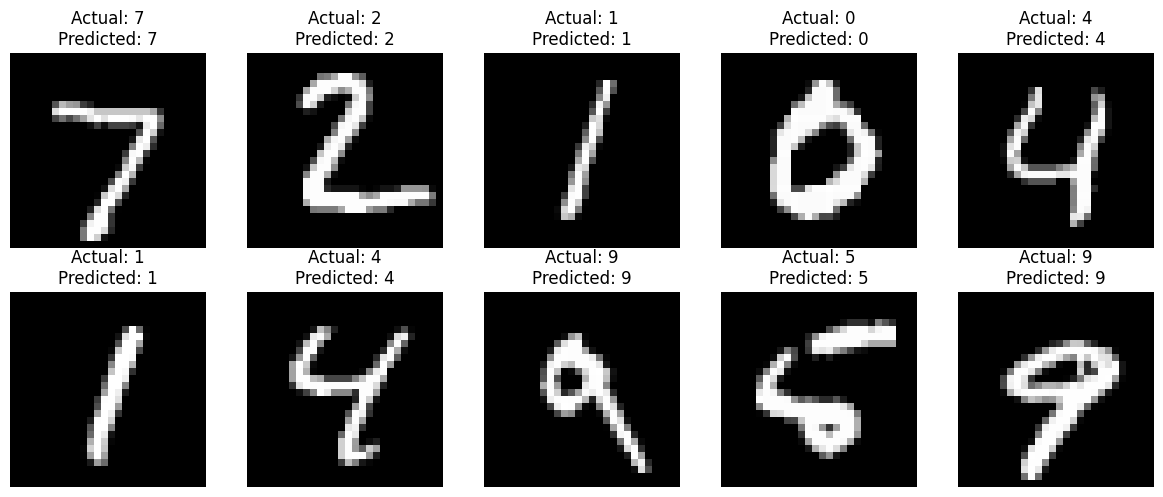

In [ ]:
import matplotlib.pyplot as plt

model.eval()

fig, axes = plt.subplots(2, 5, figsize=(12, 5))

for i, ax in enumerate(axes.flat):

    image, actual_label = test_dataset[i]

    input_image = image.unsqueeze(0)

    with torch.no_grad():
        output = model(input_image)
        predicted_label = torch.argmax(output, dim=1).item()

    ax.imshow(image.squeeze(), cmap="gray")
    ax.set_title(f"Actual: {actual_label}\nPredicted: {predicted_label}")
    ax.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
torch.save(model.state_dict(), "mnist_model.pth")

print("Model saved successfully!")

Model saved successfully!


Found images: ['/content/my_digit.jpg']


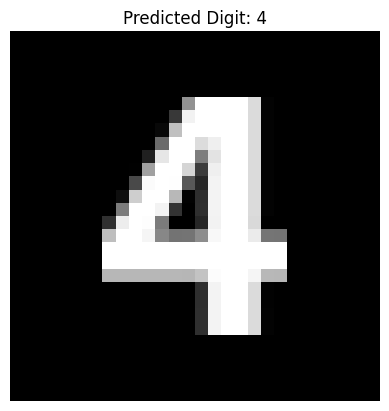

Predicted digit: 4


In [ ]:
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt
import torch
import torchvision.transforms as transforms

# Load the NEW uploaded image
import glob

image_files = glob.glob("/content/*.jpg") + glob.glob("/content/*.JPG") + glob.glob("/content/*.jpeg")

print("Found images:", image_files)

original = Image.open(image_files[0]).convert("L")

# Convert image to numpy array
arr = np.array(original)

# Separate dark handwriting from light background
threshold = arr.mean()
binary = np.where(arr < threshold, 255, 0).astype(np.uint8)

# Find the handwritten digit
coords = np.argwhere(binary > 0)

if len(coords) == 0:
    raise ValueError("Digit could not be detected")

# Find boundaries of digit
y_min, x_min = coords.min(axis=0)
y_max, x_max = coords.max(axis=0)

# Crop only the digit
digit = binary[y_min:y_max+1, x_min:x_max+1]

digit_img = Image.fromarray(digit)

# Resize while maintaining shape
digit_img.thumbnail((18, 18))

# Create MNIST-style 28x28 black background
mnist_img = Image.new("L", (28, 28), 0)

# Center the digit
x = (28 - digit_img.width) // 2
y = (28 - digit_img.height) // 2

mnist_img.paste(digit_img, (x, y))

# Convert to tensor and normalize
transform = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5,), (0.5,))
])

input_image = transform(mnist_img).unsqueeze(0)

# Make prediction
model.eval()

with torch.no_grad():
    output = model(input_image)
    probabilities = torch.softmax(output, dim=1)
    predicted_digit = torch.argmax(probabilities, dim=1).item()

# Show what the MODEL actually sees
plt.imshow(mnist_img, cmap="gray")
plt.title(f"Predicted Digit: {predicted_digit}")
plt.axis("off")
plt.show()

print("Predicted digit:", predicted_digit)

In [ ]:
# Get prediction probabilities
model.eval()

with torch.no_grad():
    output = model(input_image)
    probabilities = torch.softmax(output, dim=1)

    confidence, predicted = torch.max(probabilities, 1)

predicted_digit = predicted.item()
confidence_percent = confidence.item() * 100

print("Predicted Digit:", predicted_digit)
print(f"Confidence: {confidence_percent:.2f}%")

Predicted Digit: 4
Confidence: 89.44%


In [ ]:
from PIL import Image
import numpy as np
import matplotlib.pyplot as plt
import torch
import torchvision.transforms as transforms

def predict_digit(image_path):

    # Load image
    original = Image.open(image_path).convert("L")

    # Convert to numpy
    arr = np.array(original)

    # Separate dark digit from light background
    threshold = arr.mean()
    binary = np.where(arr < threshold, 255, 0).astype(np.uint8)

    # Find digit pixels
    coords = np.argwhere(binary > 0)

    if len(coords) == 0:
        print("Digit could not be detected.")
        return

    # Find digit boundaries
    y_min, x_min = coords.min(axis=0)
    y_max, x_max = coords.max(axis=0)

    # Crop digit
    digit = binary[y_min:y_max+1, x_min:x_max+1]
    digit_img = Image.fromarray(digit)

    # Resize while keeping shape
    digit_img.thumbnail((18, 18))

    # Create MNIST-style 28x28 image
    mnist_img = Image.new("L", (28, 28), 0)

    # Center digit
    x = (28 - digit_img.width) // 2
    y = (28 - digit_img.height) // 2

    mnist_img.paste(digit_img, (x, y))

    # Convert to tensor and normalize
    transform = transforms.Compose([
        transforms.ToTensor(),
        transforms.Normalize((0.5,), (0.5,))
    ])

    input_image = transform(mnist_img).unsqueeze(0)

    # Prediction
    model.eval()

    with torch.no_grad():
        output = model(input_image)
        probabilities = torch.softmax(output, dim=1)

        confidence, predicted = torch.max(probabilities, 1)

    predicted_digit = predicted.item()
    confidence_percent = confidence.item() * 100

    # Display processed image
    plt.imshow(mnist_img, cmap="gray")
    plt.title(
        f"Prediction: {predicted_digit} | "
        f"Confidence: {confidence_percent:.2f}%"
    )
    plt.axis("off")
    plt.show()

    print("Predicted Digit:", predicted_digit)
    print(f"Confidence: {confidence_percent:.2f}%")

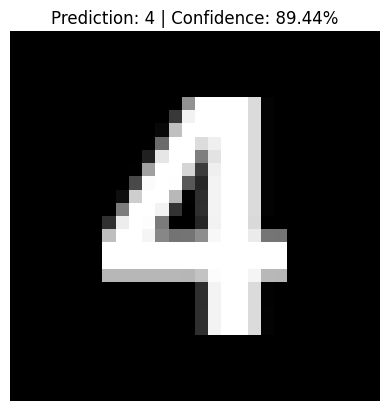

Predicted Digit: 4
Confidence: 89.44%


In [ ]:
predict_digit("/content/my_digit.jpg")

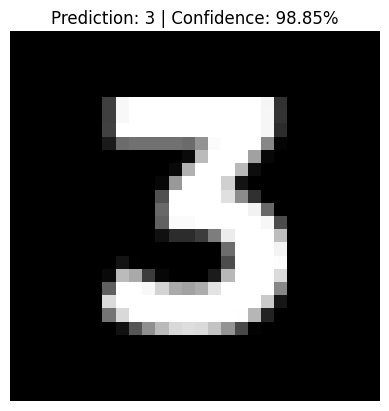

Predicted Digit: 3
Confidence: 98.85%


In [ ]:
predict_digit("/content/digit3.jpg")

In [ ]:
torch.save(model.state_dict(), "mnist_model.pth")

In [ ]:
!pip install -q gradio

In [ ]:
import gradio as gr
import numpy as np
from PIL import Image
import torch
import torchvision.transforms as transforms

def predict_drawing(data):

    if data is None:
        return "Draw a digit first."

    # Gradio ImageEditor returns a dictionary
    image = data["composite"]

    if image is None:
        return "Draw a digit first."

    image = Image.fromarray(image).convert("L")

    # Resize to MNIST size
    image = image.resize((28, 28))

    # Convert to tensor
    transform = transforms.Compose([
        transforms.ToTensor(),
        transforms.Normalize((0.5,), (0.5,))
    ])

    input_image = transform(image).unsqueeze(0)

    # Prediction
    model.eval()

    with torch.no_grad():
        output = model(input_image)
        probabilities = torch.softmax(output, dim=1)
        confidence, predicted = torch.max(probabilities, 1)

    digit = predicted.item()
    confidence = confidence.item() * 100

    return f"Predicted Digit: {digit} | Confidence: {confidence:.2f}%"

editor = gr.ImageEditor(
    type="numpy",
    label="Draw your digit here",
    height=400,
    width=400,
    brush=gr.Brush(
        colors=["#FFFFFF"],
        default_size=25
    )
)

demo = gr.Interface(
    fn=predict_drawing,
    inputs=editor,
    outputs=gr.Textbox(label="Prediction"),
    title="MNIST Handwritten Digit Recognition",
    description="Draw a white digit from 0 to 9, then click Submit."
)

demo.launch()

It looks like you are running Gradio on a hosted Jupyter notebook, which requires `share=True`. Automatically setting `share=True` (you can turn this off by setting `share=False` in `launch()` explicitly).

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://8f9f27e91965ba7a08.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
